# Tumor-edge Communication Niche Simulation

Select **cccphe** and **Run All**. Default: 8,000 cells, one tissue, five types, 75 real LR pairs, two six-LR designed MIs, four evaluation-only niches. This is a synthetic downstream experiment, separate from clinical CCC/Cox and existing Xenium outputs. The 8,000-cell simulation and model have been executed; matching completed results are reused.

Sources: [scCube](https://github.com/ZJUFanLab/scCube) expression VAE and Poisson spatial APIs; [SpiderNet simulation](https://github.com/ma-compbio-lab/SpiderNet/blob/c142960620f2fa584e8843c9acf48d719c1f2f8a/Tutorial/Simulation/SimulationData_generation.py) sender/receiver expression injection concept; [A meta-interaction basis for cell-cell communication in tissues](https://doi.org/10.64898/2026.09.21.753369). This implements a microenvironment benchmark, not a reproduction of the complete SpiderNet paper or edge encoder.

Training uses CCC reconstruction + regularization only (lambda_comp=0, lambda_reg=0.005). Original uncalibrated and composition-constrained results remain archived on NAS. The current robust error and feature scaling were selected by validation native CCC error, without using true niches or test performance.

In [1]:
%matplotlib inline
from pathlib import Path
import sys,json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path('/home/xueshuailin/CCC_Phe')
sys.path.insert(0,str(ROOT/'src'))
from phenoniche.simulation.config import SimulationConfig
from phenoniche.simulation.dependencies import prepare_environment
from phenoniche.simulation.workflow import dataset,run_experiment
from phenoniche.simulation.adapter import adapt
from phenoniche.simulation.plotting import SimulationReport
from phenoniche.training import set_seed
config=SimulationConfig.from_json(ROOT/'config/tumor_edge_simulation.json')
set_seed(config.seed)
display(pd.Series(prepare_environment()).to_frame('Installed version'))
display(pd.Series(config.to_dict()).to_frame('Configuration'))
OUTPUT=Path(config.output_dir)
def show(fig):
    display(fig)
    plt.close(fig)

/home/xueshuailin/miniconda3/envs/cccphe/lib/python3.11/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


,Installed version
scCube,2.0.0
numpy,2.3.5
pandas,2.3.3
anndata,0.12.7
scanpy,1.11.5
torch,2.3.1+cu121
POT,0.9.6.post1
scikit-learn,1.8.0


,Configuration
n_cells,8000
seed,40700
n_genes,256
n_lr,75
mi_lr_count,6
basal_lr_per_type,3
basal_lr_mean,6.0
basal_lr_offtype_mean,0.03
core_radius_um,250.0
edge_width_um,100.0


## 1. scCube expression/spatial generation and MI injection

scCube is trained on a self-contained synthetic negative-binomial reference with five type marker sets and type-specific basal ligand/receptor expression, not on hidden external patient data. Each type has three distinct real LR pairs with high own-type and low off-type expression. These type assignments are explicit synthetic assumptions, not experimentally curated biological priors. They use cell type only, never anatomical niche or MI labels. Its generated log-normalized values are inverted and clipped. Explicit count-space seed-type mean calibration restores the intended cell-type expression differences while retaining within-type relative variation, then Poisson sampling is applied. This is a hybrid simulator, not an assertion of native VAE fidelity. Raw uncalibrated counts and before/after marker audits are saved. Calibration never uses niche or MI labels. scCube Poisson coordinates are transformed into uniform half-disc coordinates in micrometers and reflected with identical radial type assignments. Mirror donors remain in the same evaluation fold. The spatial pairing-only switch is off by default; in that setting entire receiver profiles are permuted within sample/type/radial strata to preserve conditional expression marginals.

MI-1 and MI-2 use the same Tumor → Fibroblast roles but gene-disjoint characteristic LR groups. Signal is injected into sender ligands and receiver receptors only, never into final CCC.

In [2]:
adata,lr=dataset(config)
display(adata)
display(lr)
print('Source provenance:',adata.uns['simulation_provenance'])
display(pd.DataFrame(json.loads((OUTPUT/'expression_fidelity.json').read_text())['raw_scCube']))
display(pd.DataFrame(json.loads((OUTPUT/'expression_fidelity.json').read_text())['final_counts']))
display(pd.DataFrame(json.loads((OUTPUT/'expression_fidelity.json').read_text()).get('basal_LR_profiles',[])))

AnnData object with n_obs × n_vars = 8000 × 256
    obs: 'cell_id', 'cell_type', 'sample_id', 'mirror_pair', 'radius_um', 'local_x', 'local_y', 'true_niche'
    uns: 'injection_mode', 'simulation_provenance'
    obsm: 'designed_MI_activity', 'injected_receiver_activity', 'injected_sender_activity', 'spatial'

,lr_id,ligand,receptor,mi,loading,source,sender_role,receiver_role,basal_type
0,CommuSpace_HS_01036,CCL4L2,CCR1,1,0.166667,CommuSpace union; intended sender/receiver rol...,Tumor,Fibroblast,NaN
1,CommuSpace_HS_07486,TNF,FLT4,1,0.166667,CommuSpace union; intended sender/receiver rol...,Tumor,Fibroblast,NaN
2,CommuSpace_HS_07478,TNC,ITGB6,1,0.166667,CommuSpace union; intended sender/receiver rol...,Tumor,Fibroblast,NaN
3,CommuSpace_HS_01261,CDH6,PTGFRN,1,0.166667,CommuSpace union; intended sender/receiver rol...,Tumor,Fibroblast,NaN
4,CommuSpace_HS_01169,CD40LG,ITGA5,1,0.166667,CommuSpace union; intended sender/receiver rol...,Tumor,Fibroblast,NaN
...,...,...,...,...,...,...,...,...,...
70,CommuSpace_HS_06759,SEMA3D,NRP2,0,0.000000,CommuSpace union; intended sender/receiver rol...,Tumor,Fibroblast,NaN
71,CommuSpace_HS_07075,SLC6A8,LIFR,0,0.000000,CommuSpace union; intended sender/receiver rol...,Tumor,Fibroblast,NaN
72,CommuSpace_HS_02135,CSF1,CSF2RA,0,0.000000,CommuSpace union; intended sender/receiver rol...,Tumor,Fibroblast,NaN
73,CommuSpace_HS_01430,CNTF,IL6ST,0,0.000000,CommuSpace union; intended sender/receiver rol...,Tumor,Fibroblast,NaN


Source provenance: {'SpiderNet_simulation_commit': 'c142960620f2fa584e8843c9acf48d719c1f2f8a', 'basal_LR_profiles': 'Real LR identities with synthetic type-specific basal expression; no anatomical/MI labels used for basal profiles', 'expression_transform': 'invert clipped log1p values; type_mean seed-type mean calibration; Poisson sample; duplicate paired control before MI injection', 'geometry': 'scCube Poisson points -> uniform half-disc -> bilateral reflection; µm', 'scCube_commit': 'd5b423d296da17d0fd5b4d12e92262167a642445', 'seed_reference': 'synthetic negative-binomial profiles, not patient measurements', 'versions': {'POT': '0.9.6.post1', 'anndata': '0.12.7', 'numpy': '2.3.5', 'pandas': '2.3.3', 'scCube': '2.0.0', 'scanpy': '1.11.5', 'scikit-learn': '1.8.0', 'torch': '2.3.1+cu121'}}


,cell_type,own_marker_mean,other_marker_mean
0,Tumor,6.499775,7.364977
1,Normal epithelial,7.332676,7.223474
2,Fibroblast,8.419089,6.898264
3,Macrophage,6.641358,7.402469
4,T cell,6.968528,7.142640


,cell_type,own_marker_mean,other_marker_mean
0,Tumor,11.772072,0.301408
1,Normal epithelial,12.221314,0.309437
2,Fibroblast,11.455531,0.299566
3,Macrophage,11.407408,0.303858
4,T cell,11.722842,0.324365


,cell_type,LR_pairs,own_LR_gene_mean,other_type_LR_gene_mean
0,Tumor,3,5.408784,0.019387
1,Normal epithelial,3,6.105556,0.029234
2,Fibroblast,3,5.912509,0.036592
3,Macrophage,3,5.718621,0.041349
4,T cell,3,6.184433,0.036988


## 2. Exact directed CCC and evaluation-only ground truth

KNN=30, sigma=20 µm, and the existing physical-pair/opportunity-normalized CCC implementation are reused. Ground truth, designed molecular loadings and pair-weighted MI exposure are saved independently; the model adapter only passes expression, geometry, CCC and composition supervision. For a single tissue, mirrored angular sectors span the full radius and define folds using geometry only; sample folds are used for multiple replicates. Shared physical cells are purged. True labels are never used to assign or choose folds. Composition matching is checked locally, by radial strata, and by a diagnostic grouped-CV composition-only AUC.

CCC shape: (8000, 1875) effective training features: 1732
Train/validation/test centers: [4486, 1376, 1082]
Composition shape: (8000, 5)


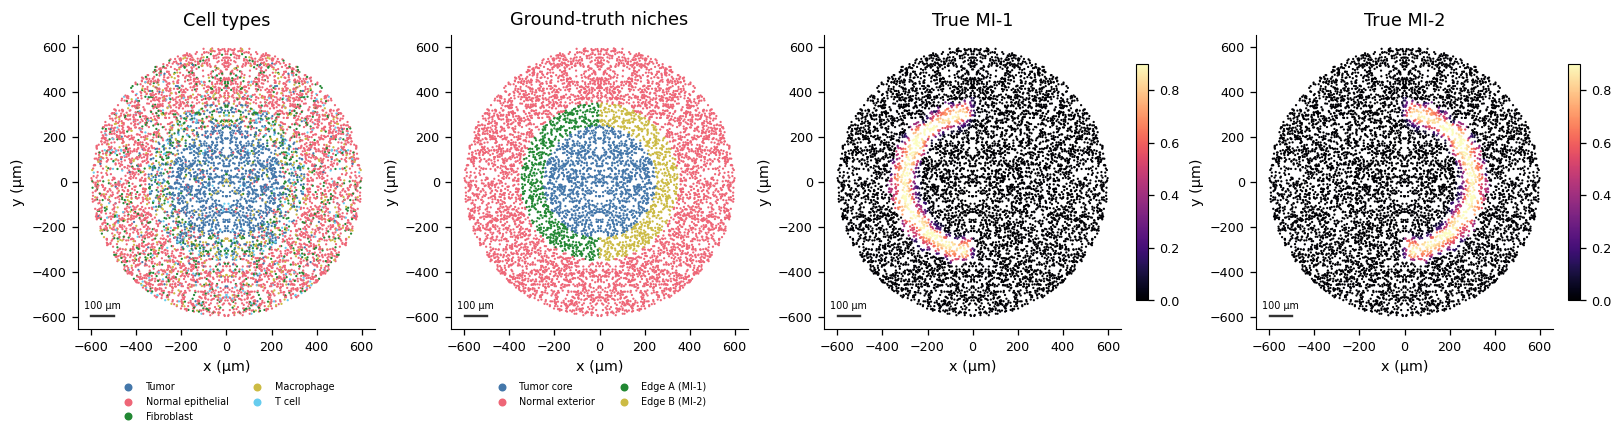

In [3]:
data=adapt(adata,lr,config,OUTPUT)
print('CCC shape:',data.targets.shape,'effective training features:',int(data.feature_mask.sum()))
print('Train/validation/test centers:',[len(r) for r in data.rows])
print('Composition shape:',data.composition_target.shape)
truth_report=SimulationReport(OUTPUT,load_results=False)
show(truth_report.ground_truth())

## 3. Train current GNN, discover niches, and run all controls

The expression-only GNN learns nonnegative 32-program Z and H. Cell-type composition reconstruction and its training loss are disabled. Sparse/nonredundant program regularization remains. There is no cell-type embedding or regulatory alignment. CCC-vector AE reuses the existing three-stage training code. Composition clustering consumes known type fractions; expression PCA uses label-free pair-weighted neighborhood expression; AE consumes precomputed CCC; GNN predicts CCC from expression/geometry with auxiliary composition supervision. These are different information conditions. The native activity head is optimized in dimensionless units and fused back into the original Linear parameters before export; inference architecture is unchanged. Program dictionary H uses training CCC prototypes only. Clustering uses a metric on Z derived from learned H and training feature scales: activity swaps between duplicate programs have zero distance when reconstructed communication is unchanged. No observed CCC vectors or true labels enter GNN inference or clustering.

GNN K=4–15 is chosen using training/validation data, never true niches. The main figure separately uses fixed K=4 for all methods. Matching cluster labels to truth is performed only for evaluation, fit on training labels and then applied to held-out test centers. Raw clusters are independently saved and shown.

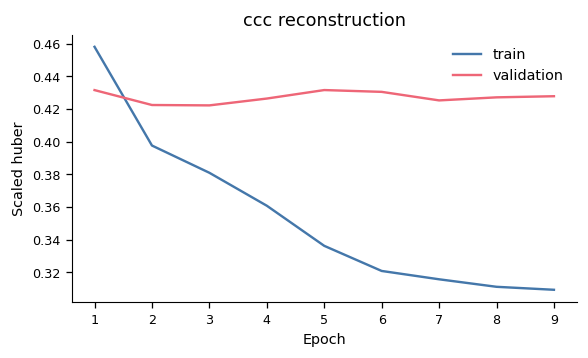

,K,silhouette,seed_stability,max_niche_cell_fraction,tiny_niche_fraction,active_niches,selection_score,eligible,selected
0,4,0.648621,1.000000,0.672238,0.00000,4,0.800000,True,True
1,5,0.648621,0.975975,0.672238,0.00000,4,0.785035,False,False
2,6,0.335844,0.518375,0.413517,0.00000,5,0.230841,False,False
3,7,0.599991,0.534619,0.662064,0.00000,6,0.454229,False,False
4,8,0.391338,0.620269,0.299419,0.00000,7,0.416823,False,False
5,9,0.373738,0.660223,0.297238,0.00000,7,0.420782,False,False
6,10,0.369493,0.696911,0.298692,0.00000,8,0.437661,False,False
7,11,0.352733,0.902071,0.301599,0.00000,9,0.543195,False,False
8,12,0.365731,0.982328,0.300145,0.00000,10,0.610074,False,False
9,13,0.327858,0.708429,0.244186,0.00436,11,0.318383,False,False


Raw unaligned clusters:


,cell_id,Cell Composition,Expression PCA,CCC-AE,CCC_Phe GNN (fixed K),CCC_Phe GNN (selected K)
0,sim_0,0,0,3,0,0
1,sim_1,1,3,1,3,2
2,sim_2,0,0,1,3,2
3,sim_3,3,3,0,0,0
4,sim_4,0,3,3,0,0


In [4]:
run_experiment(config)
report=SimulationReport(OUTPUT)
show(report.reconstruction())
display(pd.read_csv(OUTPUT/'gnn/K_selection.csv'))
print('Raw unaligned clusters:')
display(pd.read_csv(OUTPUT/'raw_clusters.csv').head())

## 4. Main comparison: Ground Truth | Composition | Expression | CCC-AE | CCC_Phe GNN

These are the actual raw cluster outputs. Colors are independently assigned per method and are not post-hoc aligned to the ground truth. The full single-tissue map is descriptive/transductive; held-out metrics below use disjoint physical cells. For multiple replicates, the figure displays a held-out replicate.

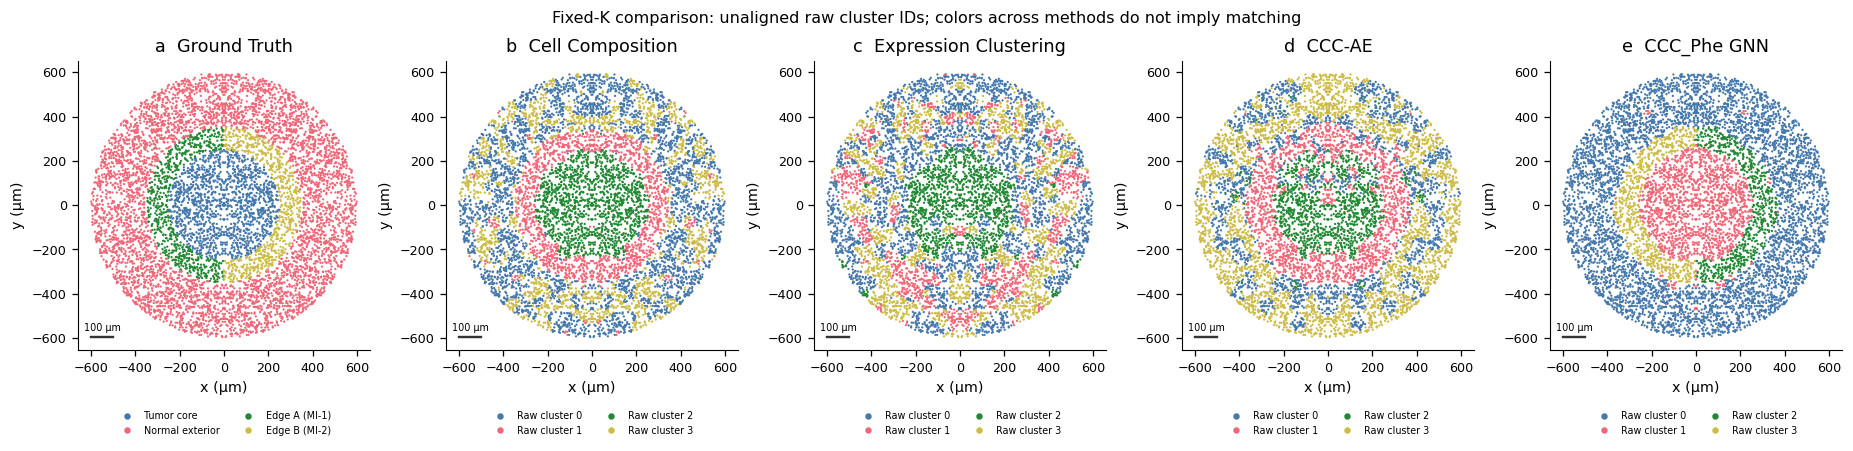

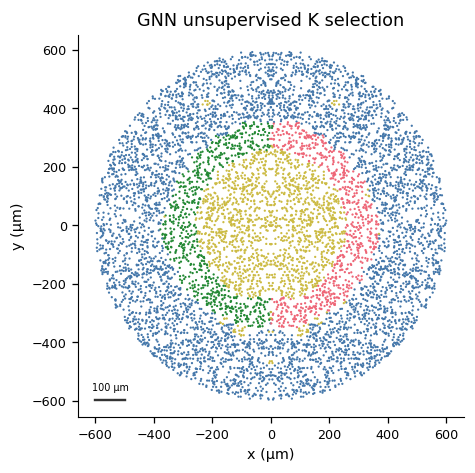

In [5]:
show(report.main_figure())
show(report.adaptive_niches())

## 5. Quantitative recovery and composition controls

All-cell/transductive and held-out results are reported separately. ARI/NMI and edge-only ARI are label permutation invariant. Edge F1/IoU and A/B accuracy use training-only evaluation mappings. The composition diagnostic classifier uses true A/B labels only here, with paired donors grouped in CV; it is not part of the niche model. Results may show failure to distinguish the two half-rings. Edge A/B have two explicit planted MI programs. Type-specific basal LR profiles supply distinct directed backgrounds for the Tumor core and Normal exterior. Overlapping microenvironments mix signals across anatomical boundaries; a perfect four-region ARI is not assumed. One synthetic realization does not establish biological causality or multi-seed robustness.

,method,evaluation,K,overall_ARI,overall_NMI,edge_F1,edge_IoU,edge_AB_ARI,edge_AB_accuracy,overall_evaluable,edge_detection_evaluable,edge_AB_evaluable,n,n_true_edge
0,Cell Composition,all_transductive,4,0.523383,0.639768,0.564214,0.392965,-0.000227,0.500000,True,True,True,8000,1366
1,Cell Composition,heldout_test,4,0.440173,0.560210,0.518272,0.349776,-0.002235,0.500000,True,True,True,1082,164
2,Expression PCA,all_transductive,4,0.177942,0.280422,0.194486,0.107718,0.001090,0.524158,True,True,True,8000,1366
3,Expression PCA,heldout_test,4,0.096197,0.286642,0.139384,0.074913,-0.001836,0.493902,True,True,True,1082,164
4,CCC-AE,all_transductive,4,0.403324,0.487319,0.511261,0.343419,0.001019,0.508785,True,True,True,8000,1366
5,CCC-AE,heldout_test,4,0.280108,0.363611,0.404794,0.253756,0.002683,0.524390,True,True,True,1082,164
6,CCC_Phe GNN (fixed K),all_transductive,4,0.917960,0.843801,0.923586,0.858020,0.838802,0.961201,True,True,True,8000,1366
7,CCC_Phe GNN (fixed K),heldout_test,4,0.973541,0.920803,0.959502,0.922156,0.880953,0.969512,True,True,True,1082,164
8,CCC_Phe GNN (selected K),all_transductive,4,0.918865,0.845898,0.925220,0.860846,0.845589,0.964129,True,True,True,8000,1366
9,CCC_Phe GNN (selected K),heldout_test,4,0.973541,0.920803,0.959502,0.922156,0.880953,0.969512,True,True,True,1082,164


,fold,0,1,2,3
0,-1,442,458,78,78
1,0,748,2944,397,397
2,1,176,948,126,126
3,2,84,834,82,82


,Diagnostic
gnn_test_CCC_Huber,0.265526
ae_test_CCC_Huber,0.277758
test_contains_edge,True
best_epoch,3
composition_only_grouped_CV_AUC,0.5
CV_groups,mirror pairs stay together; diagnostic classif...
max_mirror_local_composition_difference,0.0
radial_composition_mean_abs_difference,0.0
strict_mode_max_gene_marginal_difference,None
interpretation,Synthetic recovery diagnostics; no biological ...


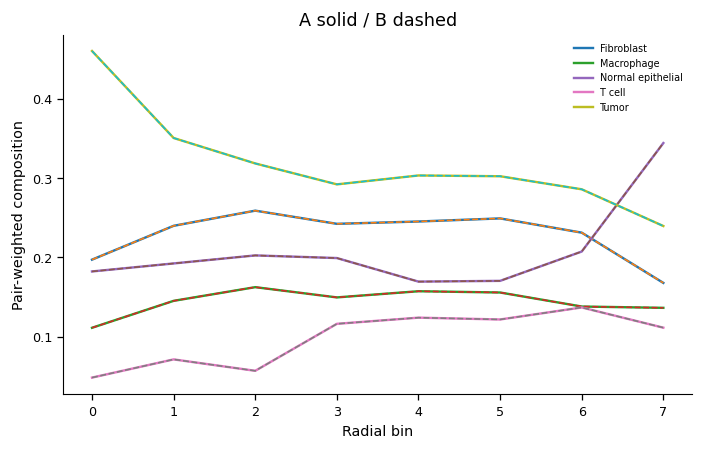

,radial_bin,cell_type,A,B,difference
0,0,Tumor,0.460260,0.460260,0.000000e+00
1,0,Normal epithelial,0.182408,0.182408,-2.980232e-08
2,0,Fibroblast,0.197286,0.197286,0.000000e+00
3,0,Macrophage,0.111413,0.111413,0.000000e+00
4,0,T cell,0.048633,0.048633,0.000000e+00
5,1,Tumor,0.350610,0.350610,0.000000e+00
6,1,Normal epithelial,0.192510,0.192511,-1.490116e-08
7,1,Fibroblast,0.239936,0.239936,-1.490116e-08
8,1,Macrophage,0.145367,0.145367,-1.490116e-08
9,1,T cell,0.071576,0.071576,0.000000e+00


In [6]:
display(pd.read_csv(OUTPUT/'metrics.csv'))
display(pd.read_csv(OUTPUT/'evaluation_split_coverage.csv'))
display(pd.Series(json.loads((OUTPUT/'diagnostics.json').read_text())).to_frame('Diagnostic'))
show(report.composition_audit())
display(pd.read_csv(OUTPUT/'radial_composition_audit.csv'))

## 6. True MI-1 / MI-2 versus recovered communication programs

Two distinct learned programs are matched by their H dictionary cosine with the designed MI-LR dictionary, without using held-out activity to choose programs. Both overall and edge-restricted test activity correlations are reported. Initial H similarity is reported separately because H uses unsupervised CCC prototype initialization; a recognizable H alone does not show the encoder learned MI activity. Partial or poor dictionary/activity recovery is shown as measured; learned programs need not equal the two designed MIs one-to-one.

,MI,program,scope,dictionary_cosine,initial_dictionary_cosine,dictionary_cosine_gain,top_LR_precision,activity_Spearman,match_policy
0,1,4,test_all,0.861806,0.853568,0.008237,1.0,0.485643,one-to-one dictionary matching only; no test a...
1,1,4,test_edge,0.861806,0.853568,0.008237,1.0,0.883829,one-to-one dictionary matching only; no test a...
2,2,10,test_all,0.866916,0.855919,0.010997,1.0,0.480985,one-to-one dictionary matching only; no test a...
3,2,10,test_edge,0.866916,0.855919,0.010997,1.0,0.878750,one-to-one dictionary matching only; no test a...


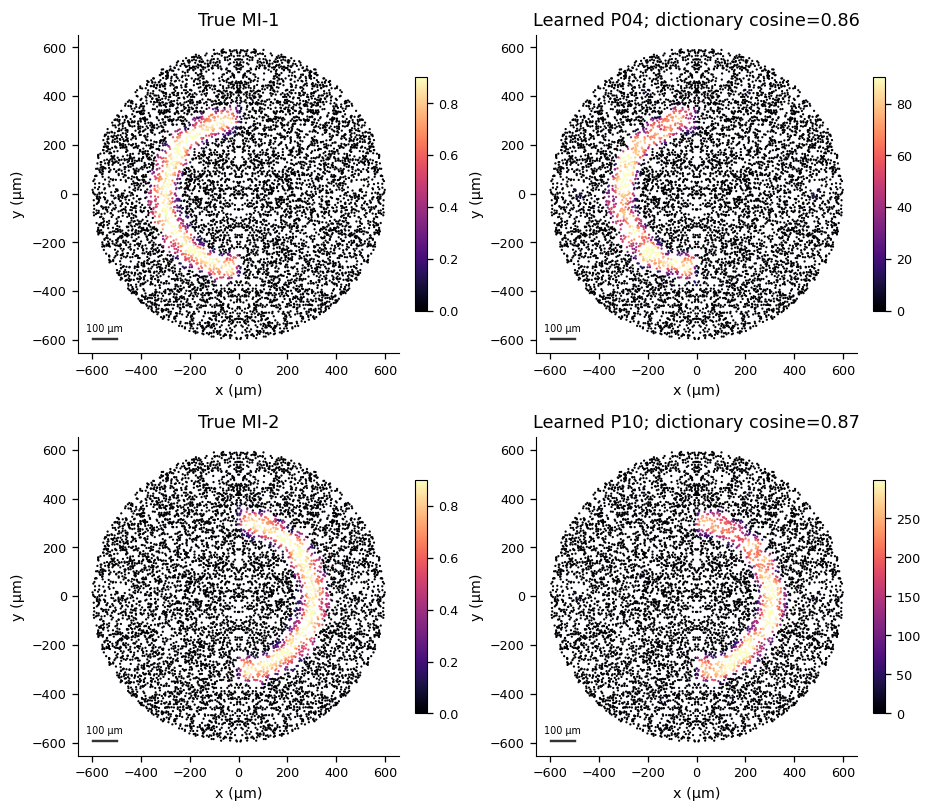

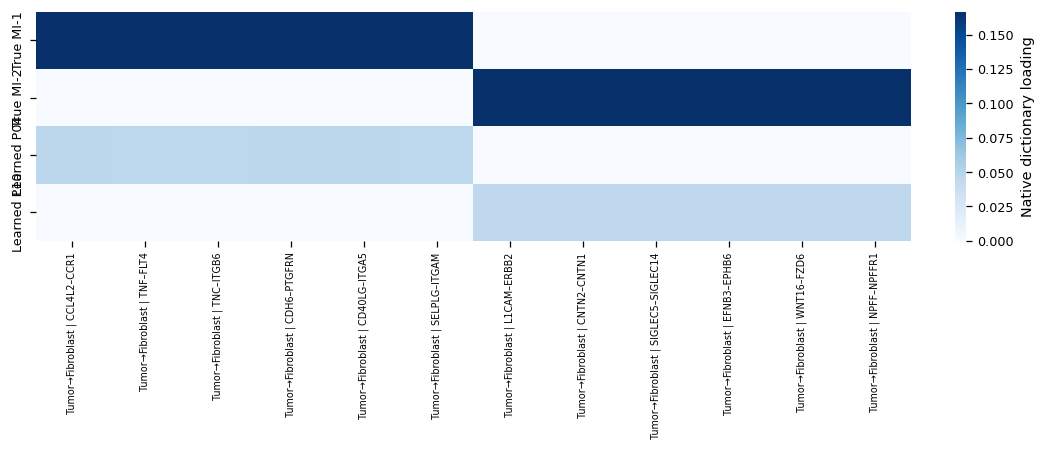

,program,rank,feature_id,ccc,sender,receiver,ligand,receptor,weight
0,1,1,161,Tumor → Fibroblast | NPFF–NPFFR1,Tumor,Fibroblast,NPFF,NPFFR1,0.034269
1,1,2,159,Tumor → Fibroblast | EFNB3–EPHB6,Tumor,Fibroblast,EFNB3,EPHB6,0.033990
2,1,3,158,Tumor → Fibroblast | SIGLEC5–SIGLEC14,Tumor,Fibroblast,SIGLEC5,SIGLEC14,0.033954
3,1,4,156,Tumor → Fibroblast | L1CAM–ERBB2,Tumor,Fibroblast,L1CAM,ERBB2,0.033664
4,1,5,157,Tumor → Fibroblast | CNTN2–CNTN1,Tumor,Fibroblast,CNTN2,CNTN1,0.033516
...,...,...,...,...,...,...,...,...,...
465,32,1,150,Tumor → Fibroblast | CCL4L2–CCR1,Tumor,Fibroblast,CCL4L2,CCR1,0.042816
466,32,2,153,Tumor → Fibroblast | CDH6–PTGFRN,Tumor,Fibroblast,CDH6,PTGFRN,0.042635
467,32,3,151,Tumor → Fibroblast | TNF–FLT4,Tumor,Fibroblast,TNF,FLT4,0.042497
468,32,4,154,Tumor → Fibroblast | CD40LG–ITGA5,Tumor,Fibroblast,CD40LG,ITGA5,0.042422


All generated data, checkpoints, CSVs, PNG/PDF: /home/nas3/biod/xueshuailin/CCC_Phe/workspace/outputs/tumor_edge_simulation_type_specific_lr


In [7]:
display(pd.read_csv(OUTPUT/'MI_matches.csv'))
show(report.recovered_programs())
show(report.dictionary())
display(pd.read_csv(OUTPUT/'gnn/programs/top_ccc.csv').groupby('program').head(5))
print('All generated data, checkpoints, CSVs, PNG/PDF:',OUTPUT)

## 7. Numerical diagnosis and validation-only selection

The optional earlier comparison records numerical tuning on the previous uniform-LR simulation; selection used validation native CCC error only. Those settings were then applied unchanged to the corrected type-specific LR simulation. These are different simulated datasets, not a same-data claim of model improvement. The prior program-coordinate clustering results are retained separately for comparison. All plots above are computed from the selected trained GNN, with no ideal region labels injected.

In [8]:
table_path=OUTPUT.parent/'comparison.csv'
if table_path.exists():
    display(pd.read_csv(table_path)[['experiment','validation_native_MSE','validation_RMS_Huber','best_epoch','robust_error']])
previous=OUTPUT/'program_coordinate_metrics.csv'
if previous.exists():
    old=pd.read_csv(previous)
    new=pd.read_csv(OUTPUT/'metrics.csv')
    comparison=pd.concat([old.assign(metric='Original program coordinates'),new.assign(metric='Learned dictionary distance')])
    keep=(comparison.method=='CCC_Phe GNN (fixed K)')&(comparison.evaluation=='heldout_test')
    display(comparison.loc[keep,['metric','overall_ARI','edge_F1','edge_AB_accuracy']])